## Imports, Setup & Dataset Quality Audit

Using: mps
Loaded cached records: 5000
Total images: 5000 | Total valid captions: 25010
Average token count: 10.44
Average lexical diversity: 0.9084
Duplicate caption occurrences: 221
Licence counts: {'1': 1431, '3': 1414, '4': 857, '5': 417, '6': 246, '2': 630, '7': 5}


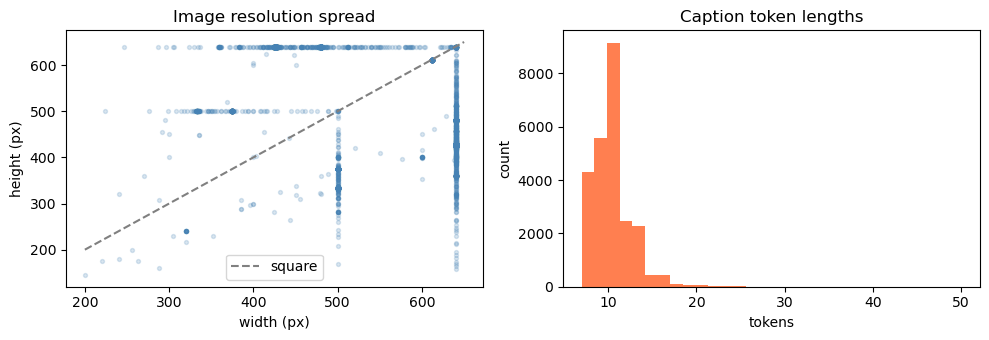

In [1]:
import math, time, copy, json, random, re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision.models import resnet50, ResNet50_Weights
from datasets import load_dataset
from transformers import BertTokenizer, BertModel

# grab available accelerator
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Using:", device)

# pin random seeds across python, numpy, and torch so splits and weights replicate
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ensure project data directory exists
DATA_DIR = Path("./multimodal_project/shared_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# check for cached splits or download and filter corrupted entries
splits_file = DATA_DIR / "coco_splits.json"
suspect_phrase = "there is no image here to provide a caption for."

if splits_file.exists():
    splits = json.loads(splits_file.read_text(encoding="utf-8"))
    all_records = splits["train"] + splits["validation"] + splits["test"]
    print("Loaded cached records:", len(all_records))
else:
    ds = load_dataset("lmms-lab/COCO-Caption2017", split="val")
    records = []
    for row in ds:
        # strip whitespace and scrub the known corrupted placeholder phrase
        cleaned = [c.strip() for c in (row["answer"] or [])
                   if isinstance(c, str) and c.strip() and c.strip().lower() != suspect_phrase]
        records.append({
            "id": int(row["id"]),
            "file_name": str(row["file_name"]),
            "width": int(row["width"]),
            "height": int(row["height"]),
            "license": str(row["license"]),
            "captions": cleaned,
        })
    # fixed random shuffle prior to carving out subsets
    random.Random(42).shuffle(records)
    splits = {"train": records[:4000], "validation": records[4000:4500], "test": records[4500:5000]}
    splits_file.write_text(json.dumps(splits, indent=2), encoding="utf-8")
    all_records = records
    print("Saved cleaned splits:", len(all_records))

# aggregate all valid captions across records to evaluate linguistic hygiene
all_texts = [c for r in all_records for c in r["captions"]]
token_lengths = []
lexical_diversity = []

for text in all_texts:
    tokens = text.lower().split()
    if len(tokens) > 0:
        token_lengths.append(len(tokens))
        # type token ratio: proportion of unique vocabulary per caption
        lexical_diversity.append(len(set(tokens)) / len(tokens))

widths = [r["width"] for r in all_records]
heights = [r["height"] for r in all_records]
norm_texts = [t.lower() for t in all_texts]

print("Total images:", len(all_records), "| Total valid captions:", len(all_texts))
print("Average token count:", round(np.mean(token_lengths), 2))
print("Average lexical diversity:", round(np.mean(lexical_diversity), 4))
print("Duplicate caption occurrences:", len(norm_texts) - len(set(norm_texts)))
print("Licence counts:", dict(Counter(r["license"] for r in all_records)))

# plot aspect ratio scatter and caption length histogram
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(widths, heights, alpha=0.2, s=8, color="steelblue")
axes[0].plot([200, 650], [200, 650], ls="--", color="grey", label="square")
axes[0].set(title="Image resolution spread", xlabel="width (px)", ylabel="height (px)")
axes[0].legend()

axes[1].hist(token_lengths, bins=30, color="coral")
axes[1].set(title="Caption token lengths", xlabel="tokens", ylabel="count")
plt.tight_layout()
plt.show()

## Feature Extraction & Splitting (Pretrained ResNet-50 & BERT)

In [2]:
img_feat_path = DATA_DIR / "image_features.pt"
txt_feat_path = DATA_DIR / "text_features.pt"

# build flat index mappings so every individual caption knows its parent image and split
all_captions, caption_image_indices, caption_splits = [], [], []
for split_name, offset, subset in [
    ("train", 0, splits["train"]),
    ("validation", 4000, splits["validation"]),
    ("test", 4500, splits["test"]),
]:
    for i, r in enumerate(subset):
        for c in r["captions"]:
            all_captions.append(c)
            caption_image_indices.append(offset + i)
            caption_splits.append(split_name)

# run feature extraction if precomputed tensors are not sitting on disk
if not (img_feat_path.exists() and txt_feat_path.exists()):
    ds_raw = load_dataset("lmms-lab/COCO-Caption2017", split="val")
    id_to_pos = {r["id"]: idx for idx, r in enumerate(all_records)}

    # ResNet-50 visual backbone: strip the final linear layer to get raw 2048-d pool5 features
    weights = ResNet50_Weights.DEFAULT
    transform = weights.transforms()
    cnn = resnet50(weights=weights)
    cnn.fc = nn.Identity()
    cnn = cnn.to(device).eval()

    img_features = torch.zeros((len(all_records), 2048), dtype=torch.float32)
    with torch.no_grad():
        for item in ds_raw:
            pos = id_to_pos[int(item["id"])]
            img_t = transform(item["image"].convert("RGB")).unsqueeze(0).to(device)
            img_features[pos] = cnn(img_t).squeeze(0).cpu()
    torch.save({"features": img_features, "image_ids": [r["id"] for r in all_records]}, img_feat_path)

    # BERT text backbone: pull contextual token states and mean pool across sequence length
    tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
    bert = BertModel.from_pretrained("bert-base-uncased").to(device).eval()

    def extract_text_features(text):
        toks = tokenizer(text, return_tensors="pt", truncation=True, max_length=64).to(device)
        with torch.no_grad():
            out = bert(**toks).last_hidden_state       # (1, seq_len, 768)
        return out.squeeze(0).mean(dim=0).cpu()        # mean-pooled (768,)

    txt_features = torch.stack([extract_text_features(c) for c in all_captions])
    torch.save({
        "features": txt_features,
        "captions": all_captions,
        "caption_image_indices": caption_image_indices,
        "caption_splits": caption_splits,
    }, txt_feat_path)

# reload tensors directly to device memory
img_pkg = torch.load(img_feat_path, map_location="cpu", weights_only=True)
txt_pkg = torch.load(txt_feat_path, map_location="cpu", weights_only=True)

image_vecs = img_pkg["features"].float().to(device)                          # (5000, 2048)
text_vecs  = txt_pkg["features"].float().to(device)                          # (25010, 768)
cap_owners = torch.tensor(txt_pkg["caption_image_indices"], device=device)  # (25010,)
texts      = txt_pkg["captions"]
image_ids  = img_pkg["image_ids"]

# construct lookup list mapping each image to all its associated caption rows
img_to_caps = [[] for _ in range(len(all_records))]
for c_idx, i_idx in enumerate(txt_pkg["caption_image_indices"]):
    img_to_caps[i_idx].append(c_idx)

# assign unique integer identifiers to distinct normalized caption texts to flag cross image caption reuse
norm_caps = [c.strip().lower() for c in texts]
unique_map = {s: i for i, s in enumerate(dict.fromkeys(norm_caps))}
text_ids = torch.tensor([unique_map[s] for s in norm_caps], device=device)

# contiguous partition boundaries: 4000 train / 500 validation / 500 test images
train_idx = torch.arange(0, 4000, device=device)
val_idx   = torch.arange(4000, 4500, device=device)
test_idx  = torch.arange(4500, 5000, device=device)

# carve out an aligned 500-sample training probe to monitor train loss on an identical gallery scale
train_probe = train_idx[torch.randperm(len(train_idx), generator=torch.Generator().manual_seed(42))[:500]]

# locate all caption rows tied to the respective evaluation partitions
val_caps   = torch.where((cap_owners >= 4000) & (cap_owners < 4500))[0]
test_caps  = torch.where((cap_owners >= 4500) & (cap_owners < 5000))[0]
probe_caps = torch.where(torch.isin(cap_owners, train_probe))[0]

print(f"Train: {len(train_idx)}   Validation: {len(val_idx)}   Test: {len(test_idx)}")
print("Image features:", tuple(image_vecs.shape), "| Text features:", tuple(text_vecs.shape))

Train: 4000   Validation: 500   Test: 500
Image features: (5000, 2048) | Text features: (25010, 768)


## Evaluation Metrics

In [3]:
def recall_at_k(scores, match_mask, ks=(1, 5, 10)):
    """
    evaluate retrieval ranking when images map to multiple valid ground-truth captions.
    rows represent queries and columns represent candidates; match_mask[i, j] marks valid pairs.
    """
    # find the highest similarity score among all valid targets for each query row
    best_match_score = scores.masked_fill(~match_mask, -1e9).max(dim=1, keepdim=True).values
    # count how many incorrect candidates beat the best matching candidate (0 means top-1 match)
    rank = ((scores > best_match_score) & (~match_mask)).sum(dim=1)
    out = {f"R@{k}": (rank < k).float().mean().item() for k in ks}
    out["MRR"] = (1.0 / (rank.float() + 1.0)).mean().item()
    return out


@torch.no_grad()
def retrieval_metrics(score_fn, img_idx, cap_idx):
    """compute bidirectional retrieval metrics (R@1, R@5, R@10, and MRR) over a gallery"""
    S = score_fn(img_idx, cap_idx)   # similarity grid (e.g., 500 images x ~2500 captions)

    # direct ground truth: caption belongs strictly to that exact image index
    strict_mask = (img_idx.unsqueeze(1) == cap_owners[cap_idx].unsqueeze(0))
    # text collision check: credit an image if it owns an identical normalized string
    same_text = (text_ids[cap_idx].unsqueeze(0) == text_ids[cap_idx].unsqueeze(1))
    match_mask = (strict_mask.float() @ same_text.float()) > 0

    # calculate image to text and transpose for text to image
    i2t = recall_at_k(S, match_mask)
    t2i = recall_at_k(S.T, match_mask.T)

    out = {}
    for k in ("R@1", "R@5", "R@10", "MRR"):
        out[f"{k} i→t"] = i2t[k]
        out[f"{k} t→i"] = t2i[k]
    out["mean R@1"] = 0.5 * (i2t["R@1"] + t2i["R@1"])
    return out

## Models A & B: DualEncoder with info_nce vs. triplet_loss

In [4]:
class DualEncoder(nn.Module):
    """projects visual and text features into a shared l2-normalised embedding space"""
    def __init__(self, img_dim=2048, text_dim=768, hidden=256):
        super().__init__()
        # single linear projection per modality into the joint representation space
        self.img_tower  = nn.Linear(img_dim, hidden)
        self.text_tower = nn.Linear(text_dim, hidden)

    def embed_image(self, values):
        # normalize to unit sphere for cosine similarity via dot product
        return F.normalize(self.img_tower(values), dim=-1)

    def embed_text(self, values):
        return F.normalize(self.text_tower(values), dim=-1)

    def forward(self, img_values, text_values):
        return self.embed_image(img_values), self.embed_text(text_values)

    def score_gallery(self, img_idx, cap_idx):
        # compute similarity across all query image and candidate caption pairings
        return self.embed_image(image_vecs[img_idx]) @ self.embed_text(text_vecs[cap_idx]).T


# symmetric infonce contrastive loss with off diagonal collision masking
def info_nce(img_embeddings, text_embeddings, cap_batch_idx, temperature=0.07):
    logits = (img_embeddings @ text_embeddings.T) / temperature
    # mask out pairs that share duplicate caption text to avoid penalising valid matches
    same_text = (text_ids[cap_batch_idx].unsqueeze(1) == text_ids[cap_batch_idx].unsqueeze(0))
    eye = torch.eye(len(logits), dtype=torch.bool, device=logits.device)
    logits = logits.masked_fill(same_text & (~eye), -1e4)

    # bidirectional cross entropy over batch elements
    targets = torch.arange(len(logits), device=logits.device)
    return (F.cross_entropy(logits, targets) + F.cross_entropy(logits.T, targets)) / 2


# margin triplet loss supporting all negative sum or hardest negative max
def triplet_loss(img_embeddings, text_embeddings, cap_batch_idx, margin=0.2, mode="max"):
    scores = img_embeddings @ text_embeddings.T
    pos = scores.diag()
    # identify text collisions to zero out false negative penalties
    same_text = (text_ids[cap_batch_idx].unsqueeze(1) == text_ids[cap_batch_idx].unsqueeze(0))

    cost_t = (margin + scores - pos.unsqueeze(1)).clamp_min(0.0).masked_fill(same_text, 0.0)
    cost_i = (margin + scores - pos.unsqueeze(0)).clamp_min(0.0).masked_fill(same_text, 0.0)

    if mode == "max":
        # focus gradient updates exclusively on the most violating negative sample
        return (cost_t.max(dim=1).values.mean() + cost_i.max(dim=0).values.mean()) / 2
    # sum penalties across all active margin violators
    return (cost_t.sum(dim=1).mean() + cost_i.sum(dim=0).mean()) / 2


# dual encoder training loop using validation recall@1 for early stopping
def train_dual_encoder(loss_type="infonce", mode="max", margin=0.2, warmup=2,
                       seed=0, epochs=30, batch_size=128, temperature=0.07):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    rng = random.Random(seed)
    model = DualEncoder().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

    best_r1, best_state, best_epoch, wait = -1.0, None, 0, 0
    history = {"train_loss": [], "val_r1": []}

    for epoch in range(epochs):
        model.train()
        order = train_idx[torch.randperm(len(train_idx))].tolist()
        epoch_loss = 0.0

        for start in range(0, len(order), batch_size):
            rows = order[start : start + batch_size]
            # randomly pick one valid caption per image in the current batch
            caps = [rng.choice(img_to_caps[i]) for i in rows]
            ix = torch.tensor(rows, device=device)
            cx = torch.tensor(caps, device=device)

            optimizer.zero_grad()
            a, t = model(image_vecs[ix], text_vecs[cx])
            if loss_type == "infonce":
                loss = info_nce(a, t, cx, temperature)
            else:
                # use sum loss during warmup epochs before switching to hard negative mining
                ep_mode = "sum" if (mode == "max" and epoch < warmup) else mode
                loss = triplet_loss(a, t, cx, margin=margin, mode=ep_mode)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(rows)

        # evaluate retrieval recall on the validation gallery
        model.eval()
        val_metrics = retrieval_metrics(model.score_gallery, val_idx, val_caps)
        val_r1 = val_metrics["mean R@1"]
        history["train_loss"].append(epoch_loss / len(train_idx))
        history["val_r1"].append(val_r1)

        # checkpoint when validation recall improves; stop after patience window lapses
        if val_r1 > best_r1 + 1e-6:
            best_r1, best_epoch, wait = val_r1, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= 7:
                break

    # restore best checkpoint before returning
    model.load_state_dict(best_state)
    model.eval()
    return model, history, best_epoch

In [5]:
# train model a with infonce and sweep triplet loss configurations across three random seeds
SEEDS = (0, 1, 2)
models_A, histories_A = {}, {}
models_B, histories_B = {}, {}
sweep_rows = []

# 1. baseline dual encoder runs using symmetric infonce loss
for s in SEEDS:
    m, hist, best_ep = train_dual_encoder(loss_type="infonce", seed=s)
    models_A[s], histories_A[s] = m, hist
    sweep_rows.append({
        "Model / Setting": "Model A: InfoNCE (T=0.07)",
        "seed": s,
        "early stop epoch": best_ep,
        "val mean R@1 (%)": max(hist["val_r1"]) * 100
    })

# 2. compare violation summation against hardest negative mining and margin variations
triplet_settings = [
    ("Model B: Sum of Violations (m=0.2)", "sum", 0.2, 0),
    ("Model B: Hardest Negative (m=0.2)",  "max", 0.2, 0),
    ("Model B: MH + Warmup (m=0.1)",       "max", 0.1, 2),
    ("Model B: MH + Warmup (m=0.2)",       "max", 0.2, 2),
    ("Model B: MH + Warmup (m=0.3)",       "max", 0.3, 2),
]

for label, mode, margin, warmup in triplet_settings:
    for s in SEEDS:
        m, hist, best_ep = train_dual_encoder(
            loss_type="triplet",
            mode=mode,
            margin=margin,
            warmup=warmup,
            seed=s
        )
        sweep_rows.append({
            "Model / Setting": label,
            "seed": s,
            "early stop epoch": best_ep,
            "val mean R@1 (%)": max(hist["val_r1"]) * 100
        })
        # retain the balanced margin configuration as the primary model b candidate
        if label == "Model B: MH + Warmup (m=0.2)":
            models_B[s], histories_B[s] = m, hist

# aggregate validation recall and convergence stability across runs
df_sweep = pd.DataFrame(sweep_rows)
display(df_sweep.groupby("Model / Setting")[["val mean R@1 (%)", "early stop epoch"]].agg(["mean", "std"]).round(2))

val mean R@1 (%)       early stop epoch  \
                                               mean   std             mean   
Model / Setting                                                              
Model A: InfoNCE (T=0.07)                     33.67  0.54             8.67   
Model B: Hardest Negative (m=0.2)             31.86  0.37            24.67   
Model B: MH + Warmup (m=0.1)                  31.02  0.30            25.00   
Model B: MH + Warmup (m=0.2)                  33.06  0.80            27.67   
Model B: MH + Warmup (m=0.3)                  32.24  0.34            29.33   
Model B: Sum of Violations (m=0.2)            32.25  0.99            16.33   

                                           
                                      std  
Model / Setting                            
Model A: InfoNCE (T=0.07)            1.53  
Model B: Hardest Negative (m=0.2)    5.03  
Model B: MH + Warmup (m=0.1)         5.57  
Model B: MH + Warmup (m=0.2)         1.53  
Model B: MH + Warmup (m=0.3)         0.58  
Model B: Sum of Violations (m=0.2)  11.15

## Model C: MultimodalNetworkExtended with make_pairs & train_two_tower

In [6]:
class MultimodalNetworkExtended(nn.Module):
    """
    two tower concatenation + mlp matcher.
    projects image and text, concatenates [a, t], and outputs a raw match logit.
    """
    def __init__(self, img_dim=2048, text_dim=768, hidden=256, dropout=0.2):
        super().__init__()
        self.img_fc  = nn.Linear(img_dim, hidden)
        self.text_fc = nn.Linear(text_dim, hidden)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, img_vec, text_vec):
        a = F.normalize(self.img_fc(img_vec), dim=-1)
        t = F.normalize(self.text_fc(text_vec), dim=-1)
        return self.classifier(torch.cat([a, t], dim=-1)).squeeze(-1)

    @torch.no_grad()
    def score_gallery(self, img_idx, cap_idx, chunk=8192):
        """score all (img_idx, cap_idx) pairs in chunks using the trained mlp classifier"""
        a = F.normalize(self.img_fc(image_vecs[img_idx]), dim=-1)
        t = F.normalize(self.text_fc(text_vecs[cap_idx]), dim=-1)
        fc1, fc2 = self.classifier[0], self.classifier[3]
        d = a.shape[1]
        # pre project linear combinations to speed up pair-wise evaluation
        pa = F.linear(a, fc1.weight[:, :d], fc1.bias)
        pt = F.linear(t, fc1.weight[:, d:], None)

        n_i, n_c = len(a), len(t)
        S = torch.empty((n_i, n_c), dtype=torch.float32, device=device)
        flat = S.view(-1)
        for start in range(0, n_i * n_c, chunk):
            idx = torch.arange(start, min(start + chunk, n_i * n_c), device=device)
            h = F.relu(pa[idx // n_c] + pt[idx % n_c])
            flat[start : start + len(h)] = fc2(h).squeeze(-1)
        return S


def make_pairs(batch_img_ids, rng, neg_shifts=(1, 2, 3, 4)):
    """
    construct matched (label 1) and mismatched (label 0) pairs in both
    retrieval directions using roll shifts.
    """
    pos_caps = [rng.choice(img_to_caps[i]) for i in batch_img_ids]
    ix = torch.tensor(batch_img_ids, device=device)
    cx = torch.tensor(pos_caps, device=device)

    img_list, txt_list, lbl_list = [ix], [cx], [torch.ones(len(ix), device=device)]
    for s in neg_shifts:
        shift = (s * 13) % max(1, len(ix) - 1) + 1
        rolled_c = cx.roll(shift)
        rolled_i = ix.roll(shift)
        # ensure circularly shifted text does not collide with the true positive string
        valid = (text_ids[cx] != text_ids[rolled_c])
        if valid.any():
            img_list.extend([ix[valid], rolled_i[valid]])
            txt_list.extend([rolled_c[valid], cx[valid]])
            lbl_list.extend([torch.zeros(valid.sum(), device=device), torch.zeros(valid.sum(), device=device)])

    return torch.cat(img_list), torch.cat(txt_list), torch.cat(lbl_list)


def train_two_tower(dropout=0.2, seed=0, epochs=30, batch=128, lr=1e-3, weight_decay=0.01):
    """two tower training routine tracking validation recall@1 for early stopping"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    rng = random.Random(seed)
    model = MultimodalNetworkExtended(dropout=dropout).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()

    best_r1, best_state, best_epoch, wait = -1.0, None, 0, 0
    history = {"train_loss": [], "val_r1": []}

    for epoch in range(epochs):
        model.train()
        order = train_idx[torch.randperm(len(train_idx))].tolist()
        epoch_loss = 0.0

        for i in range(0, len(order), batch):
            batch_imgs = order[i : i + batch]
            if len(batch_imgs) < 4:
                continue
            a_idx, t_idx, y = make_pairs(batch_imgs, rng)
            opt.zero_grad()
            logits = model(image_vecs[a_idx], text_vecs[t_idx])
            # balance loss weighting between positive matches and sampled negatives
            pos_mask = (y == 1.0)
            loss = 0.5 * (criterion(logits[pos_mask], y[pos_mask]) + criterion(logits[~pos_mask], y[~pos_mask]))
            loss.backward()
            opt.step()
            epoch_loss += loss.item() * len(batch_imgs)

        # evaluate on validation gallery
        model.eval()
        val_metrics = retrieval_metrics(model.score_gallery, val_idx, val_caps)
        val_r1 = val_metrics["mean R@1"]
        history["train_loss"].append(epoch_loss / len(train_idx))
        history["val_r1"].append(val_r1)

        # preserve best checkpoint on validation recall improvements
        if val_r1 > best_r1 + 1e-6:
            best_r1, best_epoch, wait = val_r1, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= 7:
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, history, best_epoch


# sweep dropout (0.0 vs 0.2) across 3 seeds for model c
models_C, histories_C = {}, {}
c_rows = []
for dp in (0.0, 0.2):
    for s in SEEDS:
        m, hist, best_ep = train_two_tower(dropout=dp, seed=s)
        c_rows.append({
            "dropout": dp,
            "seed": s,
            "early stop epoch": best_ep,
            "val mean R@1 (%)": max(hist["val_r1"]) * 100
        })
        # keep the regularised checkpoint as the primary model c candidate
        if dp == 0.2:
            models_C[s], histories_C[s] = m, hist

display(pd.DataFrame(c_rows).groupby("dropout")[["val mean R@1 (%)", "early stop epoch"]].agg(["mean", "std"]).round(2))

val mean R@1 (%)       early stop epoch      
                    mean   std             mean   std
dropout                                              
0.0                 6.31  0.28            19.33  5.86
0.2                 6.52  0.06            26.00  6.08

## Final Held-Out Test Evaluation, Efficiency Table & Heatmaps

In [7]:
# evaluate models a, b, and c across all 3 seeds on train500, validation, and test sets
all_models = {
    "Model A (InfoNCE)": models_A,
    "Model B (Triplet Hard)": models_B,
    "Model C (Two Tower MLP)": models_C,
}

eval_rows = []
scoring_ms = {}

for name, seed_dict in all_models.items():
    for s, model in seed_dict.items():
        for split_name, (g_i, g_c) in [
            ("Train500", (train_probe, probe_caps)),
            ("Val500",   (val_idx, val_caps)),
            ("Test500",  (test_idx, test_caps)),
        ]:
            m_dict = retrieval_metrics(model.score_gallery, g_i, g_c)
            eval_rows.append({
                "Model": name, "Split": split_name, "seed": s,
                # convert metric proportions to percentage points for clean reporting
                **{k: v * 100 for k, v in m_dict.items()}
            })

    # measure gallery scoring latency over the full 500x2503 evaluation grid
    t0 = time.time()
    _ = seed_dict[0].score_gallery(test_idx, test_caps)
    scoring_ms[name] = round((time.time() - t0) * 1000, 2)

df_eval = pd.DataFrame(eval_rows)

print("=== HELD OUT TEST SET REPORT (500 Images, 2,503 Captions) — Mean ± SD over 3 Seeds ===")
cols = ["R@1 i→t", "R@5 i→t", "R@10 i→t", "MRR i→t", "R@1 t→i", "R@5 t→i", "R@10 t→i", "MRR t→i"]
display(df_eval[df_eval["Split"] == "Test500"].groupby("Model")[cols].agg(["mean", "std"]).round(2))

# compute total parameter footprints and benchmark full gallery scoring latency
eff_table = pd.DataFrame({
    "parameters": {name: sum(p.numel() for p in d[0].parameters()) for name, d in all_models.items()},
    "test gallery scoring time (ms)": scoring_ms,
})
display(eff_table)

=== HELD OUT TEST SET REPORT (500 Images, 2,503 Captions) — Mean ± SD over 3 Seeds ===


R@1 i→t       R@5 i→t       R@10 i→t       MRR i→t  \
                           mean   std    mean   std     mean   std    mean   
Model                                                                        
Model A (InfoNCE)         35.33  1.60   68.40  0.80    82.27  1.55   50.23   
Model B (Triplet Hard)    36.20  0.40   70.67  1.10    83.80  1.25   51.40   
Model C (Two Tower MLP)    4.87  0.42   21.60  0.53    38.07  2.86   15.03   

                              R@1 t→i       R@5 t→i       R@10 t→i        \
                          std    mean   std    mean   std     mean   std   
Model                                                                      
Model A (InfoNCE)        0.68   27.28  0.14   62.86  0.60    79.38  0.50   
Model B (Triplet Hard)   0.32   27.67  0.56   63.68  0.93    80.06  0.58   
Model C (Two Tower MLP)  0.55    5.93  0.27   24.43  1.24    41.10  0.60   

                        MRR t→i        
                           mean   std  
Model                                  
Model A (InfoNCE)         43.63  0.26  
Model B (Triplet Hard)    44.06  0.36  
Model C (Two Tower MLP)   16.59  0.48

,parameters,test gallery scoring time (ms)
Model A (InfoNCE),721408,0.22
Model B (Triplet Hard),721408,0.16
Model C (Two Tower MLP),852993,5.58


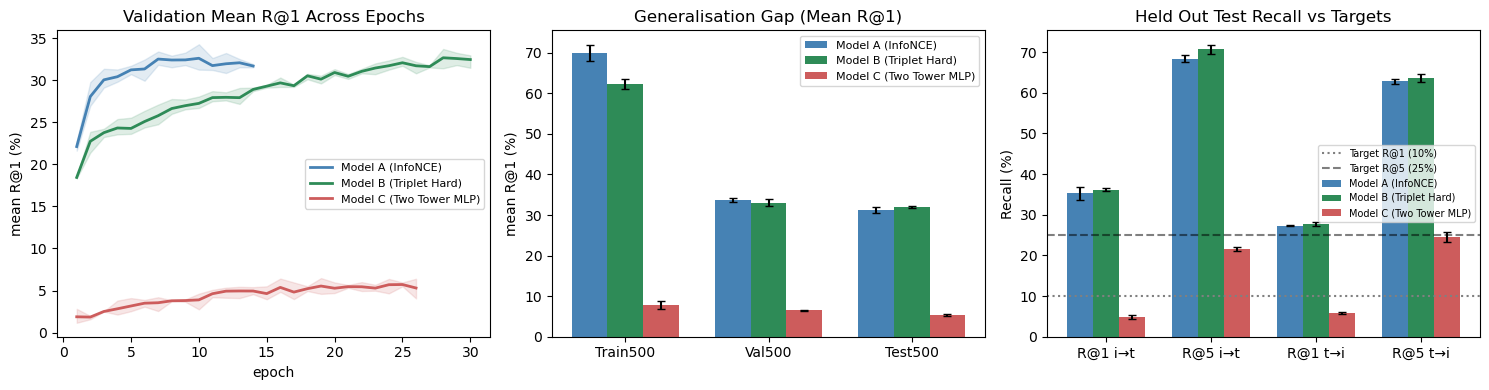

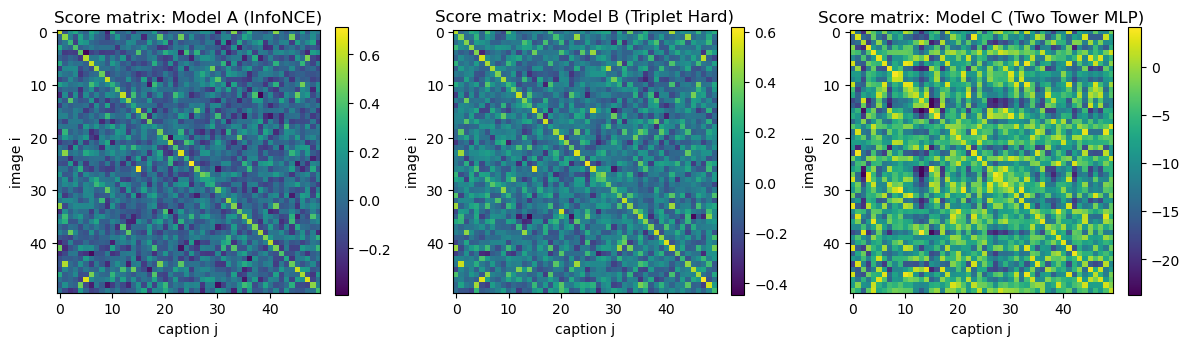

In [8]:
# plot validation trajectory, generalisation drop, and test performance against target baselines
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
colors = {"Model A (InfoNCE)": "steelblue", "Model B (Triplet Hard)": "seagreen", "Model C (Two Tower MLP)": "indianred"}

# 1. validation recall@1 progression across training epochs
for name, h_dict in [("Model A (InfoNCE)", histories_A), ("Model B (Triplet Hard)", histories_B), ("Model C (Two Tower MLP)", histories_C)]:
    # align to shortest run length across seeds for uniform plotting
    L = min(len(h["val_r1"]) for h in h_dict.values())
    y = np.array([[ r * 100 for r in h["val_r1"][:L] ] for h in h_dict.values()])
    ep = np.arange(1, L + 1)
    axes[0].plot(ep, y.mean(0), label=name, color=colors[name], lw=2)
    axes[0].fill_between(ep, y.min(0), y.max(0), color=colors[name], alpha=0.15)
axes[0].set(title="Validation Mean R@1 Across Epochs", xlabel="epoch", ylabel="mean R@1 (%)")
axes[0].legend(fontsize=8)

# 2. inspect train vs val vs test drop across models
x_s = np.arange(3)
for idx, name in enumerate(all_models.keys()):
    sub = df_eval[df_eval["Model"] == name].groupby("Split")["mean R@1"]
    means = [sub.mean().loc[sp] for sp in ("Train500", "Val500", "Test500")]
    sds   = [sub.std().loc[sp]  for sp in ("Train500", "Val500", "Test500")]
    axes[1].bar(x_s + (idx - 1) * 0.25, means, width=0.25, yerr=sds, capsize=3, color=colors[name], label=name)
axes[1].set_xticks(x_s, ["Train500", "Val500", "Test500"])
axes[1].set(title="Generalisation Gap (Mean R@1)", ylabel="mean R@1 (%)")
axes[1].legend(fontsize=8)

# 3. test set recall compared to target thresholds
test_df = df_eval[df_eval["Split"] == "Test500"]
m_keys = ["R@1 i→t", "R@5 i→t", "R@1 t→i", "R@5 t→i"]
x_m = np.arange(len(m_keys))
for idx, name in enumerate(all_models.keys()):
    sub = test_df[test_df["Model"] == name][m_keys]
    axes[2].bar(x_m + (idx - 1) * 0.25, sub.mean(), width=0.25, yerr=sub.std(), capsize=3, color=colors[name], label=name)
axes[2].axhline(10, ls=":", color="grey", label="Target R@1 (10%)")
axes[2].axhline(25, ls="--", color="black", alpha=0.5, label="Target R@5 (25%)")
axes[2].set_xticks(x_m, m_keys)
axes[2].set(title="Held Out Test Recall vs Targets", ylabel="Recall (%)")
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

# visual inspection of pairwise similarity matrices for the first 50 test items
first_caps = torch.tensor([img_to_caps[i.item()][0] for i in test_idx[:50]], device=device)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, d) in zip(axes, all_models.items()):
    S_50 = d[0].score_gallery(test_idx[:50], first_caps).detach().cpu().numpy()
    im = ax.imshow(S_50, cmap="viridis")
    ax.set(title=f"Score matrix: {name}", xlabel="caption j", ylabel="image i")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## Ethical Subgroup Audit & Qualitative Examples

In [9]:
# evaluate demographic disparities on text-to-image queries across gender-referenced subsets
male_words   = {"man", "men", "boy", "boys", "male", "males", "guy", "guys", "gentleman", "father", "husband", "son"}
female_words = {"woman", "women", "girl", "girls", "female", "females", "lady", "ladies", "mother", "wife", "daughter"}

def gender_group(sentence):
    words = set(re.findall(r"[a-z]+", sentence.lower()))
    m, f = bool(words & male_words), bool(words & female_words)
    if m and not f: return "Male-referenced"
    if f and not m: return "Female-referenced"
    if m and f:     return "Both Male & Female"
    return "Unmarked / Non human"

groups = np.array([gender_group(texts[c]) for c in test_caps.tolist()])
# ground truth matching: exact image ownership expanded to cover duplicate identical captions
strict_t = (test_idx.unsqueeze(1) == cap_owners[test_caps].unsqueeze(0))
same_t   = (text_ids[test_caps].unsqueeze(0) == text_ids[test_caps].unsqueeze(1))
match_t2i = ((strict_t.float() @ same_t.float()) > 0).T   # (2503, 500)

audit_rows = []
for name, d in all_models.items():
    # score gallery for text to image queries
    S_t2i = d[0].score_gallery(test_idx, test_caps).T
    best_pos = S_t2i.masked_fill(~match_t2i, -1e9).max(dim=1, keepdim=True).values
    # count how many wrong image candidates strictly outrank the top matching image
    rank = ((S_t2i > best_pos) & (~match_t2i)).sum(dim=1).cpu().numpy()

    for g in ("Male-referenced", "Female-referenced", "Both Male & Female", "Unmarked / Non human"):
        mask = (groups == g)
        audit_rows.append({
            "Subgroup": g, "Queries (N)": int(mask.sum()), "Model": name,
            "R@1 t→i (%)": round(float((rank[mask] < 1).mean() * 100), 2),
            "R@5 t→i (%)": round(float((rank[mask] < 5).mean() * 100), 2),
        })

display(pd.DataFrame(audit_rows).pivot(index=["Subgroup", "Queries (N)"], columns="Model", values=["R@1 t→i (%)", "R@5 t→i (%)"]))


# inspect qualitative retrieval candidates in both directions for individual test queries
@torch.no_grad()
def show_retrieval_examples(model, test_pos=0, k=3):
    img_row = test_idx[test_pos]
    cap_row = torch.tensor([img_to_caps[img_row.item()][0]], device=device)
    gold_ids = {text_ids[c].item() for c in img_to_caps[img_row.item()]}

    i2t_scores = model.score_gallery(img_row.unsqueeze(0), test_caps).squeeze(0)
    t2i_scores = model.score_gallery(test_idx, cap_row).squeeze(1)

    print(f"=== Query Image ID {image_ids[img_row.item()]} | Reference: {texts[cap_row.item()]} ===")
    print("Image → caption:")
    # retrieve and display top matching captions for the image query
    for rank, pos in enumerate(i2t_scores.topk(k).indices.tolist(), start=1):
        cand_c = test_caps[pos].item()
        marker = "  [correct]" if text_ids[cand_c].item() in gold_ids else ""
        print(f"  {rank}. {texts[cand_c]}{marker}")

    print("\nCaption → image ID:")
    # retrieve and display top matching images for the text query
    for rank, pos in enumerate(t2i_scores.topk(k).indices.tolist(), start=1):
        cand_i = test_idx[pos].item()
        marker = "  [correct]" if cand_i == img_row.item() else ""
        print(f"  {rank}. Image {image_ids[cand_i]} ({all_records[cand_i]['captions'][0]}){marker}")
    print()

show_retrieval_examples(models_B[0], test_pos=0)
show_retrieval_examples(models_B[0], test_pos=1)

R@1 t→i (%)                         \
Model                            Model A (InfoNCE) Model B (Triplet Hard)   
Subgroup             Queries (N)                                            
Both Male & Female   17                      11.76                  11.76   
Female-referenced    180                     30.00                  31.67   
Male-referenced      408                     26.72                  28.19   
Unmarked / Non human 1897                    27.31                  28.10   

                                                               R@5 t→i (%)  \
Model                            Model C (Two Tower MLP) Model A (InfoNCE)   
Subgroup             Queries (N)                                             
Both Male & Female   17                             0.00             23.53   
Female-referenced    180                            6.11             70.00   
Male-referenced      408                            4.17             59.56   
Unmarked / Non human 1897                           6.11             63.47   

                                                         \
Model                            Model B (Triplet Hard)   
Subgroup             Queries (N)                          
Both Male & Female   17                           41.18   
Female-referenced    180                          73.33   
Male-referenced      408                          60.29   
Unmarked / Non human 1897                         63.10   

                                                          
Model                            Model C (Two Tower MLP)  
Subgroup             Queries (N)                          
Both Male & Female   17                             5.88  
Female-referenced    180                           27.78  
Male-referenced      408                           23.77  
Unmarked / Non human 1897                          24.35

=== Query Image ID 73157 | Reference: A bus traveling on a freeway next to other traffic. ===
Image → caption:
  1. A double decker bus driving down a street.
  2. A  small bus traveling down a street.
  3. A red double decker bus driving down a city street.

Caption → image ID:
  1. Image 787939 (There are not many passengers on the bus.)
  2. Image 73157 (A bus traveling on a freeway next to other traffic.)  [correct]
  3. Image 312689 (A blue and white train is moving on the rails.)

=== Query Image ID 829359 | Reference: A man reaches into the air with a tennis racket, in an attempt to hit a flying tennis ball. ===
Image → caption:
  1. A young black male serving a tennis ball on a tennis court  [correct]
  2. there is a male tennis player wearing a blue shirt playing on the court
  3. Professional tennis player on clay serving the ball

Caption → image ID:
  1. Image 715155 (a tennis player swings his tennis racket)
  2. Image 112318 (A man standing on a tennis court waves to some